In [115]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [116]:
df = sns.load_dataset('titanic')
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [117]:
df.shape

(891, 15)

In [118]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB


In [119]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [120]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [121]:
df['sex'].unique()

<StringArray>
['male', 'female']
Length: 2, dtype: str

In [122]:
df['class'].unique()

['Third', 'First', 'Second']
Categories (3, str): ['First', 'Second', 'Third']

In [123]:
df['embarked'].unique()

<StringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str

## Data Cleaning

In [124]:
df = df.drop(columns=['deck', 'alive', 'adult_male', 'who', 'embark_town'])

In [125]:
df.isnull().sum()

survived      0
pclass        0
sex           0
age         177
sibsp         0
parch         0
fare          0
embarked      2
class         0
alone         0
dtype: int64

In [126]:
embarked_md = df['embarked'].mode()[0]
df['embarked'] = df['embarked'].fillna(embarked_md)

In [127]:
df['age'] = df['age'].fillna(df['age'].median())

In [128]:
df.isnull().sum()

survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
embarked    0
class       0
alone       0
dtype: int64

In [129]:
df.dtypes

survived       int64
pclass         int64
sex              str
age          float64
sibsp          int64
parch          int64
fare         float64
embarked         str
class       category
alone           bool
dtype: object

## Data Visualization

In [130]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,False
1,1,1,female,38.0,1,0,71.2833,C,First,False
2,1,3,female,26.0,0,0,7.9250,S,Third,True
3,1,1,female,35.0,1,0,53.1000,S,First,False
4,0,3,male,35.0,0,0,8.0500,S,Third,True


Text(0.5, 0, 'Survival Status')

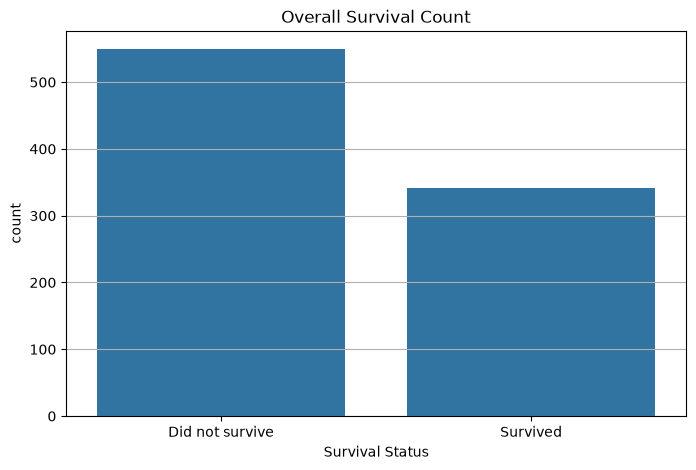

In [131]:
plt.figure(figsize=(8, 5))
plt.grid(True, axis='y')
sns.countplot(data=df, x='survived')
plt.title('Overall Survival Count')
plt.xticks([0, 1], ['Did not survive', 'Survived'])
plt.xlabel('Survival Status')

In [132]:
print(df['survived'].value_counts())
print(f'Survival rate: {df['survived'].mean()*100:.1f}')

survived
0    549
1    342
Name: count, dtype: int64
Survival rate: 38.4


The countplot compares the number of passengers who did and did not survive in Titanic.

342 passengers out of 891 passengers survived, giving a survival rate of 38.4%. This makes it clear that more than half of the passengers did  not make it. However, the survival was likely not random, the following charts will explore whether other factors like age, gender and class played a role in who survived.

Text(0.5, 1.0, 'Male vs Female Survival Status')

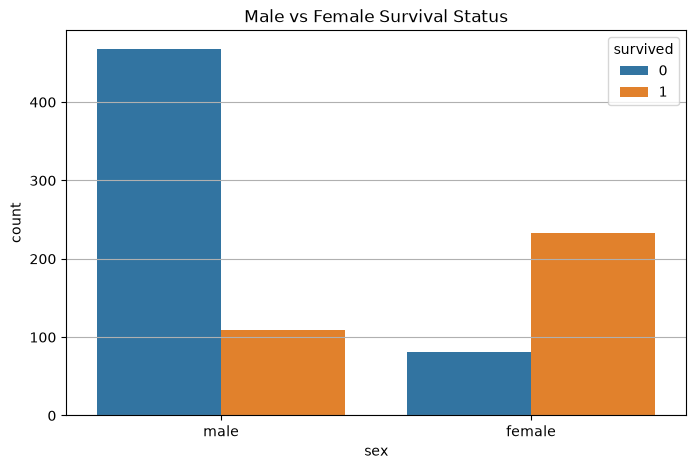

In [133]:
plt.figure(figsize=(8, 5))
plt.grid(True, axis='y')
sns.countplot(data=df, x='sex',hue='survived')
plt.title("Male vs Female Survival Status")

In [134]:
print(df.groupby('sex')['survived'].count())
print(df.groupby('sex')['survived'].value_counts())

sex
female    314
male      577
Name: survived, dtype: int64
sex     survived
female  1           233
        0            81
male    0           468
        1           109
Name: count, dtype: int64


In [135]:
print(df.groupby('sex')['survived'].agg(total='count', survived='sum', rate='mean'))

        total  survived      rate
sex                              
female    314       233  0.742038
male      577       109  0.188908


The countplot compares the number of females and males who did and did not survive titanic.

Out of 314 females, 233 survived making the survival rate 74.2%. Whereas out of 577 males, 109 made it and the survival rate was 18.9%.
This shows that the survival rate for females was likely 3.4x times more than that of males, which reflects that women were given more priority for survival.

<Axes: xlabel='class', ylabel='count'>

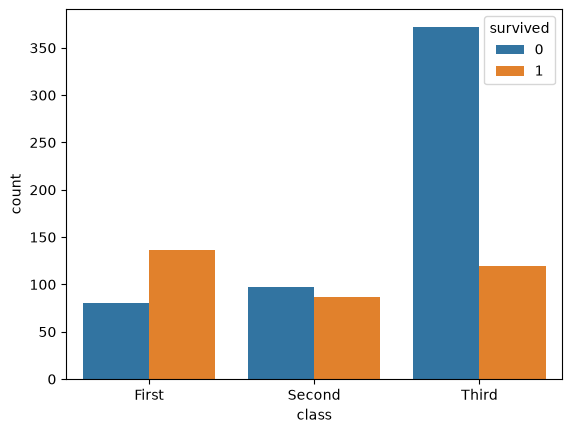

In [136]:
sns.countplot(data=df, x='class', hue='survived')

In [137]:
print(df.groupby('class', observed=True)['survived'].agg(total='count', survived='sum', rate='mean'))

        total  survived      rate
class                            
First     216       136  0.629630
Second    184        87  0.472826
Third     491       119  0.242363


The countplot compares the number of passengers who did and did not make it through the titanic disaster.

Out of 216 first class passengers, 136 survived, whereas out of 184 second class passengers 87 made it alive and out of 491 third class passengers, 119 made it alive. The survival rate was 62.9% in first class, 47.2% in second class and 24.2% in third class.

This shows that the first class passengers were 2.4x likely to survive than third class passengers possibly because first class cabins were located closer to the lifeboats.

<Axes: title={'center': 'Age distribution of the titanic passengers'}, xlabel='age', ylabel='Count'>

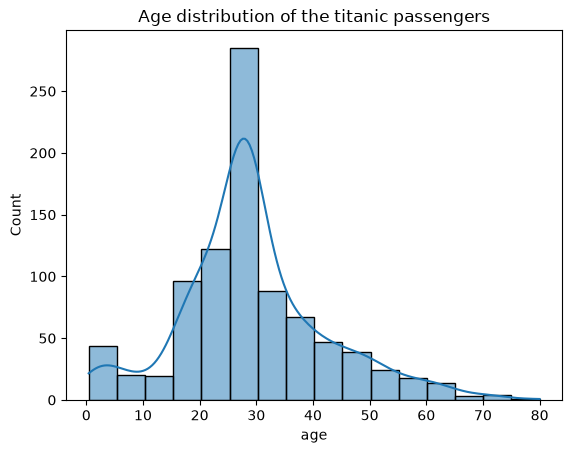

In [138]:
plt.title("Age distribution of the titanic passengers")
sns.histplot(data=df, x='age', kde=True, binwidth=5)

In [139]:
print(df['age'].min())
print(df['age'].max())

0.42
80.0


The histogram shows the age distribution of the passengers in the titanic.

Most of the passengers were in their late 20s, with the distribution peaking around age 27-28. The graph is right skewed meaning that there were more young passengers compared to older ones. There is also a small but noticeable amount of children under the age of 5 and very few passengers above 60. The youngest passenger was under 1 and the oldest passenger was 80 years old.

**Note:** 177 missing age values were filled with the median age of 28 during data cleaning, which may cause the artificial spike around that age in this plot.

Text(0.5, 1.0, 'Survival count across different age groups')

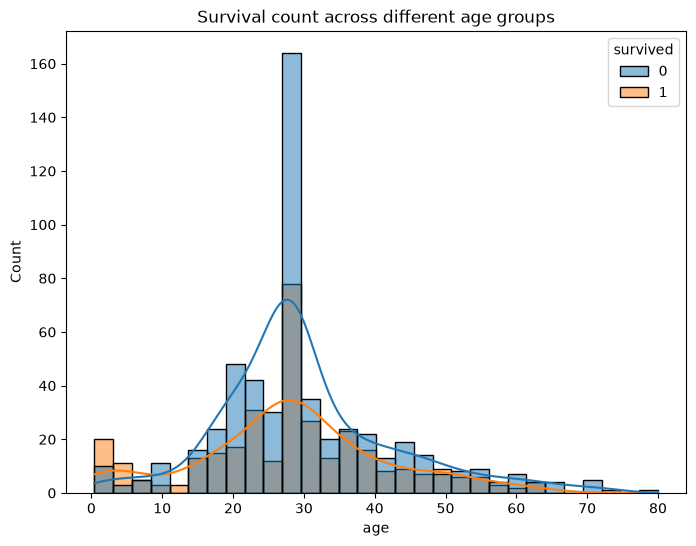

In [140]:
plt.figure(figsize=(8,6))
sns.histplot(data=df, x='age', kde=True, hue='survived', alpha=0.5)
plt.title("Survival count across different age groups")

The histogram compares the survival rate of passengers according to their age.

According to the plot, the survival rate of children below the age of 10 is higher than death rate. Passengers between the age group of 15 to 35 had the worst survival rate while passengers above 35 seem to have a better survival rate compared to the 15-35 age group.
The blue kde curve peaks at around 27-28, meaning most of the non-survivors were young adults. The orange kde curve is flatter and peaks at around 25, meaning survivors were spread evenly across different age groups

Text(0.5, 1.0, 'Passengers count from each Embarkation Port')

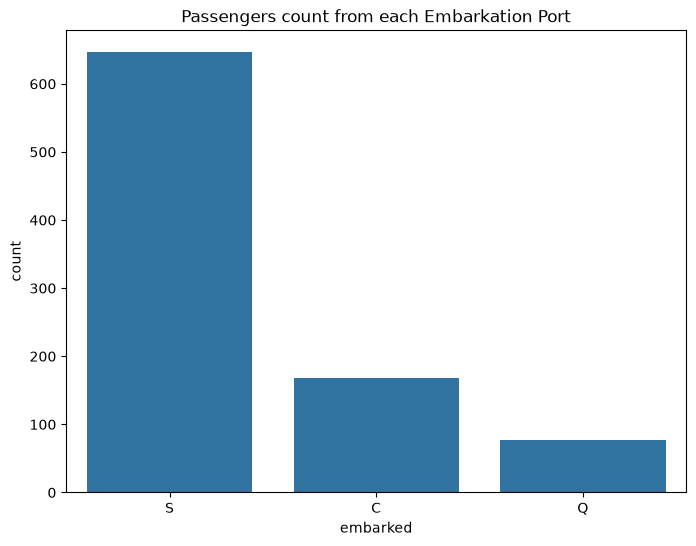

In [141]:
plt.figure(figsize=(8,6))
sns.countplot(data=df, x='embarked')
plt.title("Passengers count from each Embarkation Port")

In [142]:
df['embarked'].value_counts()

embarked
S    646
C    168
Q     77
Name: count, dtype: int64

The countplot shows the number of passengers from each embarkation port.

Out of 891 passengers, 646 boarded from Southampton, 168 boarded from Cherbourg and 77 boarded from Queenstown. This makes sense since Southampton was the primary departure port of titanic while Cherbourg and Queenstown were brief stops before heading to New York.

<Axes: xlabel='family_size', ylabel='count'>

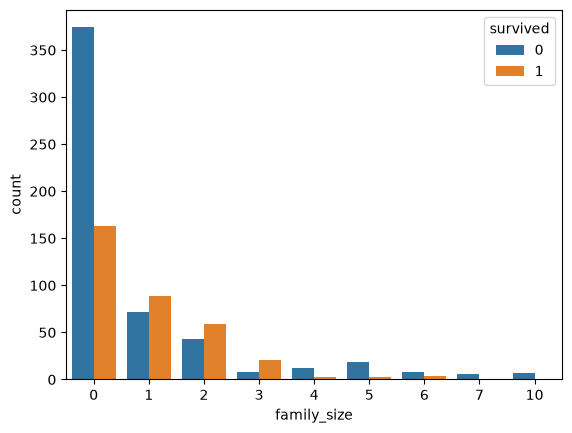

In [143]:
df['family_size'] = df['sibsp'] + df['parch']
sns.countplot(data=df, x='family_size', hue='survived')


The countplot compares survival rate to family size.

Passengers with no family members were half as likely to survive whereas, passengers with 1-3 family members were more likely to survive.Passengers with 5 and 6 family members had a very low survival rate while passengers with 7 and 10 family members had no survival rate at all.

Most of the passengers who survived had no family members though likely due to their number being the highest. Overall passengers with 3 family members had the best overall ratio for survival.

### Conclusion

**Key Findings**

1. Most of the passengers in Titanic did not make it alive as the survival rate was only 38.4%.

2. The survivors were mostly women and children likely due to women and children first policy.

3. Passengers on first class had the best survival rate while nearly half of the passengers from second class survived and only 24.2% of the passengers from  third class made it alive.

4. Passengers with 1-3 family members had higher survival rate compared to those with more or no family members.


**Limitations**

- The survival count and rate according to age is not exact due to 177 missing age values that were filled with the median age 28, which may have skewed the age analysis.

- The dataset only contains 891 passengers out of the 2,224 people aboard the Titanic, so the findings may not represent the full picture.

**Future Work**

- A machine learning classification model such as Logistic Regression or Random Forest could be built to predict whether a passenger survived based on features like gender, age, passenger class, and family size.

- This EDA has identified the most influential features (gender, class, age) which would serve as the starting point for building that model.

